In [130]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def graficar_matriz_confusion(y_test, y_pred, labels=None, title="Matriz de Confusión"):
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(cmap=plt.cm.Blues)
    plt.title(title)
    plt.show()


In [131]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, recall_score, precision_score, make_scorer
import pandas as pd
import numpy as np
import algoritmos_clasificacion as t

m_values = [0.5, 1, 5]

nd_values = ["./Datos_preprocesados/modelo1_vent1.csv", "./Datos_preprocesados/modelo1_ven2.csv", "./Datos_preprocesados/modelo1_vent3.csv",
             "./Datos_preprocesados/modelo1_vent5.csv","./Datos_preprocesados/modelo1_vent7.csv","./Datos_preprocesados/modelo1_vent10.csv"]

def split_bayes(ruta_dataset):

    # Cargar dataset
    S = pd.read_csv(ruta_dataset)

    # Features y target
    
    y = S["dia_lluvioso"]
    X = S.drop(columns=["dia_lluvioso","fecha", "amplitud_carrasco","amplitud_salto","tprom_carrasco","tprom_salto", "fase_lunar", 
                        "int_viento_carrasco_max", "int_racha_viento_carrasco_max", "int_viento_salto_max", "int_racha_viento_salto_max"
                        ])

    # Train/test split
    X_train, X_test, y_train, y_test = t.split_data(X, y)

    return X_train, X_test, y_train, y_test

def validarNaiveBayes(X_train, y_train, hiperparams=None, random_state=42, n_splits=5, pos_label='si', nd=1):

    kf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    results = []

    scoring = {
        'accuracy': make_scorer(accuracy_score),
        'f1': make_scorer(f1_score, pos_label=pos_label),
        'recall': make_scorer(recall_score, pos_label=pos_label),
        'precision': make_scorer(precision_score, pos_label=pos_label)
    }

    for m in hiperparams:
        # Crear modelo
        model = t.NaiveBayesClassifier(m=m)
        
        # CV
        cv_results = cross_validate(model, X_train, y_train, cv=kf, scoring=scoring)

        # Guardar resultados
        row = {
            'm': m,
            'nd': nd,
            'accuracy_mean': np.mean(cv_results['test_accuracy']),
            'accuracy_std': np.std(cv_results['test_accuracy']),
            'f1_mean': np.mean(cv_results['test_f1']),
            'f1_std': np.std(cv_results['test_f1']),
            'recall_mean': np.mean(cv_results['test_recall']),
            'recall_std': np.std(cv_results['test_recall']),
            'precision_mean': np.mean(cv_results['test_precision']),
            'precision_std': np.std(cv_results['test_precision']),
        }
        results.append(row)

    df_results = pd.DataFrame(results)

    return df_results

def testearBayes(best_cfg, X_train, y_train, X_test, y_test):
    
    model = t.NaiveBayesClassifier(m=best_cfg['m'])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Calcular métricas
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, pos_label="si")
    rec = recall_score(y_test, y_pred, pos_label="si")
    prec = precision_score(y_test, y_pred, pos_label="si")


    return {
        "y_pred": y_pred,
        "accuracy": acc,
        "f1": f1,
        "recall": rec,
        "precision": prec,
    }



In [132]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, recall_score, precision_score, make_scorer
from sklearn.naive_bayes import MultinomialNB
import pandas as pd
import numpy as np

alpha_values = [0.5, 1, 5]

def split_bayes_sklearn(ruta_dataset):
    # Cargar dataset
    S = pd.read_csv(ruta_dataset)

    # Target y features
    y = S["dia_lluvioso"]
    X = S.drop(columns=["dia_lluvioso","fecha","amplitud_carrasco","amplitud_salto",
                        "tprom_carrasco","tprom_salto","fase_lunar",
                        "int_viento_carrasco_max","int_racha_viento_carrasco_max",
                        "int_viento_salto_max","int_racha_viento_salto_max"])

    # Convertir categorías a dummies (one-hot)
    X_enc = pd.get_dummies(X.astype(str))

    # Train/test split
    X_train, X_test, y_train, y_test = train_test_split(
        X_enc, y, test_size=0.2, random_state=42, stratify=y
    )

    return X_train, X_test, y_train, y_test

def validarNaiveBayes_sklearn(X_train, y_train, hiperparams=alpha_values, random_state=42, n_splits=5, pos_label='si', nd=1):
    kf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    results = []

    scoring = {
        'accuracy': make_scorer(accuracy_score),
        'f1': make_scorer(f1_score, pos_label=pos_label),
        'recall': make_scorer(recall_score, pos_label=pos_label),
        'precision': make_scorer(precision_score, pos_label=pos_label)
    }

    for alpha in hiperparams:
        # Crear modelo
        model = MultinomialNB(alpha=alpha)

        # Validación cruzada
        cv_results = cross_validate(model, X_train, y_train, cv=kf, scoring=scoring)

        # Guardar resultados
        row = {
            'alpha': alpha,
            'nd': nd,
            'accuracy_mean': np.mean(cv_results['test_accuracy']),
            'accuracy_std': np.std(cv_results['test_accuracy']),
            'f1_mean': np.mean(cv_results['test_f1']),
            'f1_std': np.std(cv_results['test_f1']),
            'recall_mean': np.mean(cv_results['test_recall']),
            'recall_std': np.std(cv_results['test_recall']),
            'precision_mean': np.mean(cv_results['test_precision']),
            'precision_std': np.std(cv_results['test_precision']),
        }
        results.append(row)

    df_results = pd.DataFrame(results)


    return df_results

def testearBayesSickit(best_cfg, X_train, y_train, X_test, y_test):
    model = MultinomialNB(alpha=best_cfg['alpha'])
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Calcular métricas
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, pos_label="si")
    rec = recall_score(y_test, y_pred, pos_label="si")
    prec = precision_score(y_test, y_pred, pos_label="si")

    
    return {
        "y_pred": y_pred,
        "accuracy": acc,
        "f1": f1,
        "recall": rec,
        "precision": prec,
    }
     

In [133]:
#modelo1_vent1 con implementacion manual
X_train1m, X_test1m, y_train1m, y_test1m = split_bayes("../Datos_preprocesados/modelo1_vent1.csv")
df_res1_1_m = validarNaiveBayes(X_train1m, y_train1m, hiperparams=m_values, nd=1)

X_train2m, X_test2m, y_train2m, y_test2m = split_bayes("../Datos_preprocesados/modelo1_vent2.csv")
df_res1_2_m = validarNaiveBayes(X_train2m, y_train2m, hiperparams=m_values,nd=2)

X_train3m, X_test3m, y_train3m, y_test3m = split_bayes("../Datos_preprocesados/modelo1_vent3.csv")
df_res1_3_m = validarNaiveBayes(X_train3m, y_train3m, hiperparams=m_values,nd=3)

X_train5m, X_test5m, y_train5m, y_test5m = split_bayes("../Datos_preprocesados/modelo1_vent5.csv")
df_res1_5_m = validarNaiveBayes(X_train5m, y_train5m, hiperparams=m_values,nd=5)

X_train7m, X_test7m, y_train7m, y_test7m = split_bayes("../Datos_preprocesados/modelo1_vent7.csv")
df_res1_7_m = validarNaiveBayes(X_train7m, y_train7m, hiperparams=m_values,nd=7)

X_train10m, X_test10m, y_train10m, y_test10m = split_bayes("../Datos_preprocesados/modelo1_vent10.csv")
df_res1_10_m = validarNaiveBayes(X_train10m, y_train10m, hiperparams=m_values,nd=10)

print("\n Resultados CV Naive Bayes manual modelo1_vent1 \n")
print(df_res1_1_m.round(4).to_string(index=False))


 Resultados CV Naive Bayes manual modelo1_vent1 

  m  nd  accuracy_mean  accuracy_std  f1_mean  f1_std  recall_mean  recall_std  precision_mean  precision_std
0.5   1         0.7553        0.0083   0.3066  0.0123       0.2440      0.0084          0.4133         0.0291
1.0   1         0.7555        0.0082   0.3070  0.0122       0.2443      0.0084          0.4139         0.0288
5.0   1         0.7555        0.0080   0.3075  0.0117       0.2449      0.0084          0.4142         0.0279


In [134]:
X_train1s, X_test1s, y_train1s, y_test1s = split_bayes_sklearn("../Datos_preprocesados/modelo1_vent2.csv")
df_res1_1_s = validarNaiveBayes_sklearn(X_train1s, y_train1s, hiperparams=m_values,nd=1)
#print(df_res1_1_s)

X_train2s, X_test2s, y_train2s, y_test2s = split_bayes_sklearn("../Datos_preprocesados/modelo1_vent2.csv")
df_res1_2_s = validarNaiveBayes_sklearn(X_train2s, y_train2s, hiperparams=m_values,nd=2)

X_train3s, X_test3s, y_train3s, y_test3s = split_bayes_sklearn("../Datos_preprocesados/modelo1_vent3.csv")
df_res1_3_s = validarNaiveBayes_sklearn(X_train3s, y_train3s, hiperparams=m_values,nd=3)

X_train5s, X_test5s, y_train5s, y_test5s = split_bayes_sklearn("../Datos_preprocesados/modelo1_vent5.csv")
df_res1_5_s = validarNaiveBayes_sklearn(X_train5s, y_train5s, hiperparams=m_values,nd=5)

X_train7s, X_test7s, y_train7s, y_test7s = split_bayes_sklearn("../Datos_preprocesados/modelo1_vent7.csv")
df_res1_7_s = validarNaiveBayes_sklearn(X_train7s, y_train7s, hiperparams=m_values,nd=7)

X_train10s, X_test10s, y_train10s, y_test10s = split_bayes_sklearn("../Datos_preprocesados/modelo1_vent10.csv")
df_res1_10_s = validarNaiveBayes_sklearn(X_train10s, y_train10s, hiperparams=m_values,nd=10)

print("\n Resultados CV Naive Bayes sklearn modelo1_vent1 \n")
print(df_res1_1_s.round(4).to_string(index=False))



 Resultados CV Naive Bayes sklearn modelo1_vent1 

 alpha  nd  accuracy_mean  accuracy_std  f1_mean  f1_std  recall_mean  recall_std  precision_mean  precision_std
   0.5   1         0.7516        0.0036   0.2573  0.0121       0.1943      0.0104          0.3811         0.0154
   1.0   1         0.7513        0.0038   0.2560  0.0115       0.1932      0.0098          0.3798         0.0155
   5.0   1         0.7516        0.0038   0.2554  0.0136       0.1923      0.0118          0.3804         0.0166


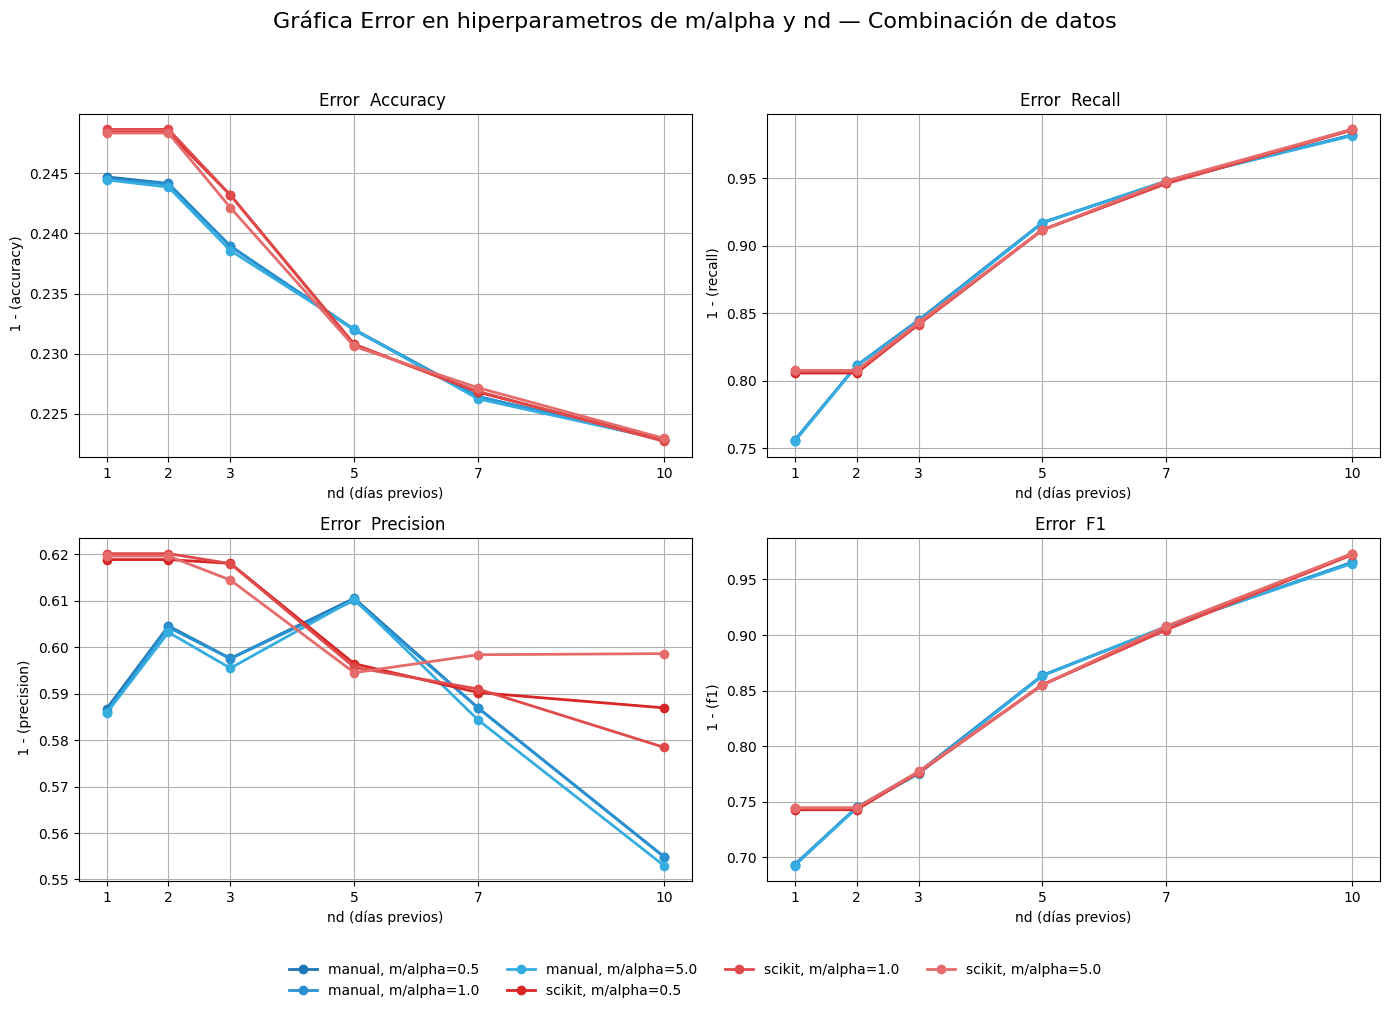

In [135]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- Configuración de tus DataFrames ---
dfs_manual_mediana = [df_res1_1_m, df_res1_2_m, df_res1_3_m, df_res1_5_m, df_res1_7_m, df_res1_10_m]
dfs_scikit_mediana = [df_res1_1_s, df_res1_2_s, df_res1_3_s, df_res1_5_s, df_res1_7_s, df_res1_10_s]

nd_values = [1,2,3,5,7,10]

# --- Consolidar resultados en un solo DataFrame ---
rows = []

def procesar_dfs(dfs, imputacion, modelo_type):
    for i, df in enumerate(dfs):
        nd = nd_values[i]
        for _, row in df.iterrows():
            rows.append({
                'imputacion': imputacion,
                'nd': nd,
                'm_alpha': row.get('m', row.get('alpha')),
                'modelo': modelo_type,
                'accuracy': row.get('Accuracy test', row.get('accuracy_mean')),
                'recall': row.get('Recall test', row.get('recall_mean')),
                'precision': row.get('Precision test', row.get('precision_mean')),
                'f1': row.get('F1 test', row.get('f1_mean'))
            })


procesar_dfs(dfs_manual_mediana, 'mediana', 'manual')
procesar_dfs(dfs_scikit_mediana, 'mediana', 'scikit')


df_plot = pd.DataFrame(rows)

# --- Convertir métricas a error y graficar ---
def graficar_error_subplots(df):
    metricas = ['accuracy','recall','precision','f1']

    colores_manual = ['#1f77b4', '#2a92d1', '#36ade0', '#61c0ff', '#7fc6ff', '#9dd0ff', '#bbe0ff', '#d8f0ff']
    colores_scikit = ['#d62728', '#e04a4a', '#e66c6c', '#eb8f8f', '#f0b3b3', '#f4d6d6', '#f9e0e0', '#fdecec']

    nombres_imputacion = {
        'mediana': 'Combinación de datos',
    }

    for imp in df['imputacion'].unique():
        fig, axes = plt.subplots(2, 2, figsize=(14,10))
        axes = axes.flatten()
        df_sub = df[df['imputacion']==imp]

        for idx, metrica in enumerate(metricas):
            ax = axes[idx]
            for modelo in ['manual','scikit']:
                df_model = df_sub[df_sub['modelo']==modelo]
                ms = sorted(df_model['m_alpha'].unique())
                
                for i, m in enumerate(ms):
                    df_m = df_model[df_model['m_alpha']==m].sort_values('nd')
                    color = colores_manual[i] if modelo == 'manual' else colores_scikit[i]
                    # Transformar a error
                    error = 1 - df_m[metrica]
                    ax.plot(df_m['nd'], error, marker='o', linestyle='-', linewidth=2,
                            color=color, label=f"{modelo}, m/alpha={m}")

            ax.set_xlabel("nd (días previos)")
            ax.set_ylabel(f" 1 - ({metrica})")
            ax.set_title(f"Error  {metrica.capitalize()} ")
            ax.set_xticks(nd_values)
            ax.grid(True)

        # Leyenda centralizada debajo de los subplots
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False, fontsize=10, bbox_to_anchor=(0.5, -0.02))

        # Título principal actualizado
        fig.suptitle(f"Gráfica Error en hiperparametros de m/alpha y nd — {nombres_imputacion[imp]}", fontsize=16)
        plt.tight_layout(rect=[0, 0.05, 1, 0.95])
        plt.show()


# --- Generar gráficos ---
graficar_error_subplots(df_plot)



In [136]:
import pandas as pd

# Listas de DataFrames
dfs_manual = [df_res1_1_m, df_res1_2_m, df_res1_3_m, df_res1_5_m, df_res1_7_m, df_res1_10_m]
dfs_scikit = [df_res1_1_s, df_res1_2_s, df_res1_3_s, df_res1_5_s, df_res1_7_s, df_res1_10_s]

# Función para obtener el mejor valor global de cualquier métrica
def mejor_global(df_list, metric='accuracy_mean'):
    # Concatenar todos los DataFrames
    df_concat = pd.concat(df_list, ignore_index=True)
    # Seleccionar la fila con el valor máximo de la métrica
    best_row = df_concat.loc[df_concat[metric].idxmax()]
    return best_row

# --- Mejor Accuracy global ---
best_accuracy_manual = mejor_global(dfs_manual, 'accuracy_mean')
best_accuracy_scikit = mejor_global(dfs_scikit, 'accuracy_mean')

# --- Mejor F1 global ---
best_f1_manual = mejor_global(dfs_manual, 'f1_mean')
best_f1_scikit = mejor_global(dfs_scikit, 'f1_mean')

# --- Mostrar resultados ---
print("=== Mejor Accuracy global (Manual) ===")
print(best_accuracy_manual.round(4).to_string())

print("\n=== Mejor F1 global (Manual) ===")
print(best_f1_manual.round(4).to_string())

print("\n=== Mejor Accuracy global (Scikit) ===")
print(best_accuracy_scikit.round(4).to_string())

print("\n=== Mejor F1 global (Scikit) ===")
print(best_f1_scikit.round(4).to_string())


=== Mejor Accuracy global (Manual) ===
m                  0.5000
nd                10.0000
accuracy_mean      0.7772
accuracy_std       0.0030
f1_mean            0.0347
f1_std             0.0093
recall_mean        0.0181
recall_std         0.0048
precision_mean     0.4451
precision_std      0.1619

=== Mejor F1 global (Manual) ===
m                 5.0000
nd                1.0000
accuracy_mean     0.7555
accuracy_std      0.0080
f1_mean           0.3075
f1_std            0.0117
recall_mean       0.2449
recall_std        0.0084
precision_mean    0.4142
precision_std     0.0279

=== Mejor Accuracy global (Scikit) ===
alpha              1.0000
nd                10.0000
accuracy_mean      0.7773
accuracy_std       0.0007
f1_mean            0.0279
f1_std             0.0056
recall_mean        0.0145
recall_std         0.0030
precision_mean     0.4215
precision_std      0.0357

=== Mejor F1 global (Scikit) ===
alpha             0.5000
nd                1.0000
accuracy_mean     0.7516
accuracy


 Res testing mejor accuracy segun CV modelo manual
Accuracy: 0.7750677506775068
F1: 0.033862433862433865
Recall: 0.017797552836484983
Precision: 0.34782608695652173

 Res testing mejor accuracy segun CV modelo de SL
Accuracy: 0.7765459472776546
F1: 0.01945945945945946
Recall: 0.010011123470522803
Precision: 0.34615384615384615


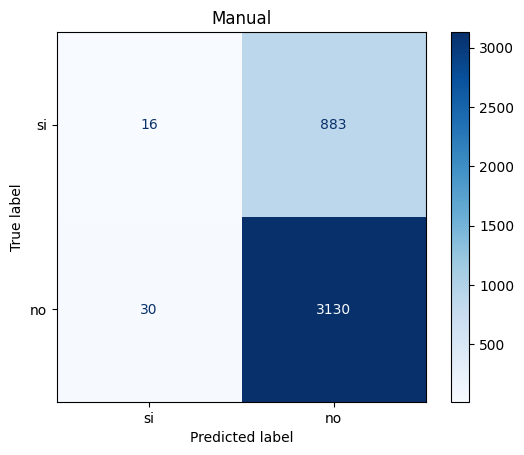

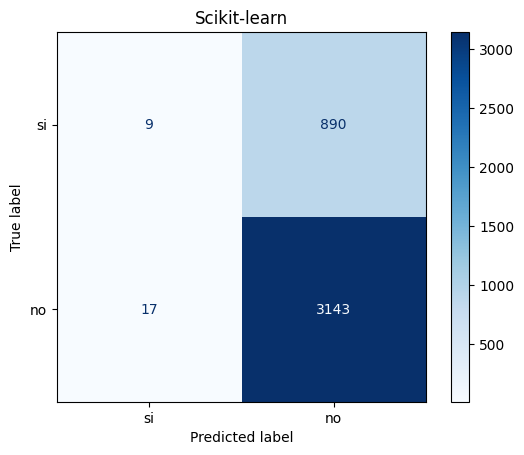

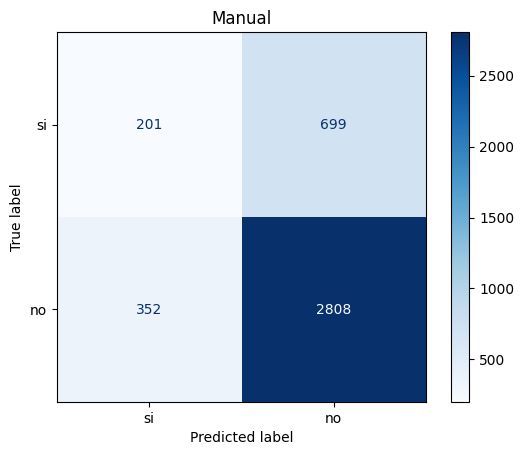


 Res testing mejor f1-score segun CV modelo manual
Accuracy: 0.7411330049261083
F1: 0.276668960770819
Recall: 0.22333333333333333
Precision: 0.36347197106690776


In [141]:
resM = testearBayes(best_accuracy_manual, X_train10m, y_train10m, X_test10m, y_test10m)
resS = testearBayesSickit(best_accuracy_scikit, X_train10s, y_train10s, X_test10s, y_test10s)

print("\n Res testing mejor accuracy segun CV modelo manual")
print("Accuracy:", resM["accuracy"])
print("F1:", resM["f1"])
print("Recall:", resM["recall"])
print("Precision:", resM["precision"])

print("\n Res testing mejor accuracy segun CV modelo de SL")
print("Accuracy:", resS["accuracy"])
print("F1:", resS["f1"])
print("Recall:", resS["recall"])
print("Precision:", resS["precision"])

graficar_matriz_confusion(y_test10m, resM["y_pred"], labels=["si", "no"], title="Manual")
graficar_matriz_confusion(y_test10s, resS["y_pred"], labels=["si", "no"], title="Scikit-learn")


resM = testearBayes(best_f1_manual, X_train1m, y_train1m, X_test1m, y_test1m)
graficar_matriz_confusion(y_test1m, resM["y_pred"], labels=["si", "no"], title="Manual")
print("\n Res testing mejor f1-score segun CV modelo manual")
print("Accuracy:", resM["accuracy"])
print("F1:", resM["f1"])
print("Recall:", resM["recall"])
print("Precision:", resM["precision"])
